# 03. Getting more from the same users, and checking the toolkit itself

**The question this notebook answers:** how many users does an experiment need, can we get a
sharper answer from the users we already have, and can we trust the toolkit's statistics?

Four things, each answered with real Criteo rows:

1. **CUPED**: use what we know about each user before the test to cancel out noise, and see the
   variance of the lift estimate drop.
2. **Power and sample size**: how many users per arm for a given lift.
3. **A/A test**: split one arm into two random halves. Nothing differs, so a good test should
   cry "significant" only 5% of the time.
4. **Power calibration**: does the calculator's "80% power" really mean 80%?

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from expkit import config, data, nb
from expkit.cuped import cuped_compare, fit_theta
from expkit.inference import compare_proportions
from expkit.power import sample_size_proportions
from expkit.report import n_, pct

ctx = nb.load()
R, con, st = ctx.results, ctx.con, ctx.settings
ctx.banner()

> Data: **Criteo Uplift v2.1**. Pipeline numbers are read from `docs/results/results.json` (written by `expkit run-all` at code commit `41db89a`) and match `docs/RESULTS.md`. Seed 42.

## 1. CUPED: variance before and after

CUPED (Controlled-experiment Using Pre-Experiment Data) subtracts the part of each user's
outcome that a pre-experiment covariate already predicts. Both arms get the same subtraction,
so the treatment effect is unchanged in expectation but the noise around it shrinks.

The Criteo file has **no pre-period metric**, so we use the 12 user features instead:

- **linear CUPED**: a straight-line prediction of `visit` from the features;
- **CUPAC**: a LightGBM model's prediction of `visit` as the covariate (the model-based variant).

Both adjustments are fitted on the **train split** and applied to the **test split**.

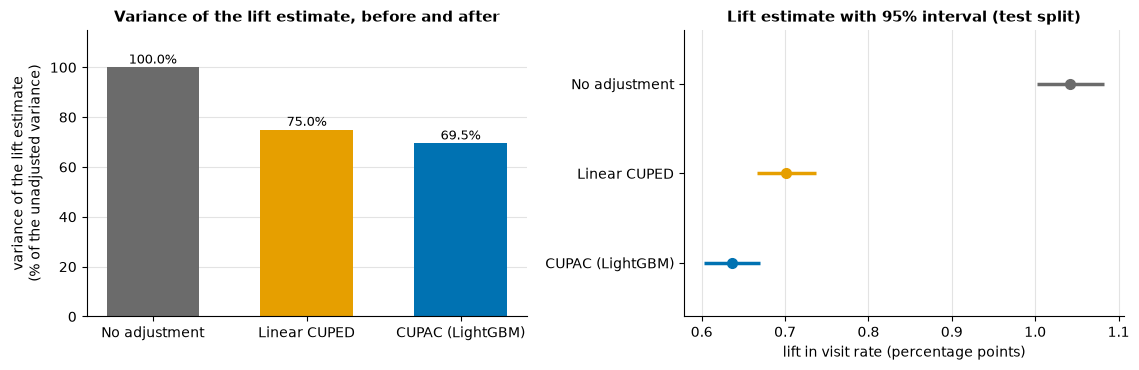

,variance reduction,users needed vs unadjusted,lift estimate,95% interval
No adjustment,0.0%,100.0%,+1.042 pp,+1.002 to +1.083 pp
Linear CUPED,25.0%,75.0%,+0.701 pp,+0.666 to +0.737 pp
CUPAC (LightGBM),30.5%,69.5%,+0.636 pp,+0.603 to +0.670 pp


In [2]:
cu = R["cuped"]["criteo"]
rows = [
    (
        "No adjustment",
        cu["raw"]["se"],
        cu["raw"]["diff"],
        cu["raw"]["ci_low"],
        cu["raw"]["ci_high"],
        0.0,
    ),
    (
        "Linear CUPED",
        cu["linear"]["se"],
        cu["linear"]["diff"],
        cu["linear"]["ci_low"],
        cu["linear"]["ci_high"],
        cu["linear"]["variance_reduction"],
    ),
    (
        "CUPAC (LightGBM)",
        cu["cupac"]["se"],
        cu["cupac"]["diff"],
        cu["cupac"]["ci_low"],
        cu["cupac"]["ci_high"],
        cu["cupac"]["variance_reduction"],
    ),
]
rel_var = [(r[1] / rows[0][1]) ** 2 for r in rows]
colors = [nb.GREY, nb.ORANGE, nb.BLUE]

fig, (a, b) = plt.subplots(1, 2, figsize=(11.5, 3.8))
bars = a.bar([r[0] for r in rows], [v * 100 for v in rel_var], color=colors, width=0.6)
for bar, v in zip(bars, rel_var):
    a.text(bar.get_x() + bar.get_width() / 2, v * 100 + 1.5, f"{v:.1%}", ha="center", fontsize=9)
a.set_ylim(0, 115)
a.set_ylabel("variance of the lift estimate\n(% of the unadjusted variance)")
a.set_title("Variance of the lift estimate, before and after")
a.grid(axis="x", visible=False)
nb.forest(
    b,
    [
        {"label": r[0], "est": r[2], "lo": r[3], "hi": r[4], "color": c}
        for r, c in zip(rows, colors)
    ],
    xlabel="lift in visit rate (percentage points)",
)
b.set_title("Lift estimate with 95% interval (test split)")
fig.tight_layout()
ctx.savefig(fig, "cuped_variance_and_estimates")

display(
    pd.DataFrame(
        {
            "variance reduction": [pct(r[5], 1) for r in rows],
            "users needed vs unadjusted": [pct(v, 1) for v in rel_var],
            "lift estimate": [f"{r[2] * 100:+.3f} pp" for r in rows],
            "95% interval": [f"{r[3] * 100:+.3f} to {r[4] * 100:+.3f} pp" for r in rows],
        },
        index=[r[0] for r in rows],
    )
)

**Reading the two panels.** The bars on the left show how much CUPED shrinks the noise, which is
the point of the method. In a perfectly randomized experiment the point estimates on the right
stay roughly where they were. If they move, the arms differ slightly in who is in them, the same
issue that notebook 02 corrects with the doubly robust (AIPW) estimate.

To see the variance reduction on its own, we resample the test split many times and compare the
spread of the two estimators.

The estimate moved by -0.34 pp (linear) and -0.41 pp (CUPAC) relative to the unadjusted +1.04 pp. For reference, the AIPW estimate from notebook 02 is +0.75 pp.

- Check: largest CUPED coefficient: recomputed `1.09568`, pipeline `1.09568` (matches)

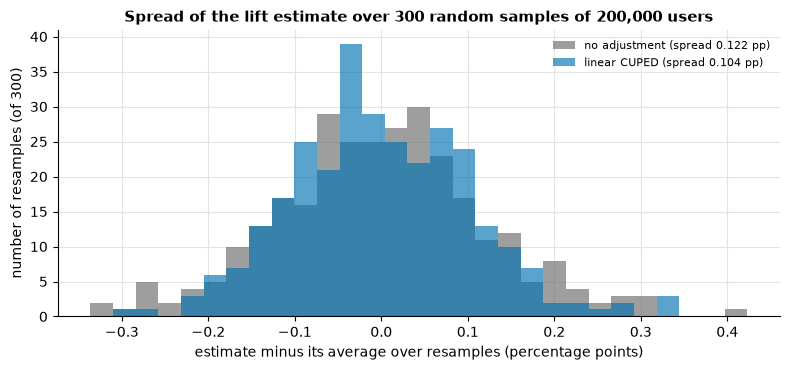

Across 300 resamples the variance of the CUPED estimate is **73.4%** of the unadjusted variance, against 75.0% predicted from the full test split in the table above.

In [3]:
move_lin = (cu["linear"]["diff"] - cu["raw"]["diff"]) * 100
move_cupac = (cu["cupac"]["diff"] - cu["raw"]["diff"]) * 100
aipw = R["effect"]["visit_adjusted"]["diff"] * 100
nb.md(
    f"The estimate moved by {move_lin:+.2f} pp (linear) and {move_cupac:+.2f} pp (CUPAC) relative "
    f"to the unadjusted {cu['raw']['diff'] * 100:+.2f} pp. For reference, the AIPW estimate from notebook 02 "
    f"is {aipw:+.2f} pp."
)

test = data.fetch_split(con, "test")
train = data.fetch_split(con, "train")
theta = fit_theta(train["visit"].astype(np.float64), train["X"])
ctx.check(
    "largest CUPED coefficient",
    float(np.abs(theta).max()),
    float(np.abs(cu["theta_linear"]).max()),
    rtol=1e-6,
)

n_sample = min(200_000, len(test["t"]) // 2)
reps = 300
rng = np.random.default_rng(config.SEED)
raw_d, adj_d = np.empty(reps), np.empty(reps)
for i in range(reps):
    idx = rng.choice(len(test["t"]), size=n_sample, replace=False)
    comp = cuped_compare(test["visit"][idx], test["X"][idx], test["t"][idx], theta=theta)
    raw_d[i], adj_d[i] = comp.raw.diff, comp.adjusted.diff
var_ratio = adj_d.var(ddof=1) / raw_d.var(ddof=1)

fig, ax = plt.subplots(figsize=(8, 3.8))
bins = np.linspace(
    min((raw_d - raw_d.mean()).min(), (adj_d - adj_d.mean()).min()) * 100,
    max((raw_d - raw_d.mean()).max(), (adj_d - adj_d.mean()).max()) * 100,
    30,
)
ax.hist(
    (raw_d - raw_d.mean()) * 100,
    bins=bins,
    color=nb.GREY,
    alpha=0.65,
    label=f"no adjustment (spread {raw_d.std(ddof=1) * 100:.3f} pp)",
)
ax.hist(
    (adj_d - adj_d.mean()) * 100,
    bins=bins,
    color=nb.BLUE,
    alpha=0.65,
    label=f"linear CUPED (spread {adj_d.std(ddof=1) * 100:.3f} pp)",
)
ax.set_xlabel("estimate minus its average over resamples (percentage points)")
ax.set_ylabel(f"number of resamples (of {reps})")
ax.set_title(f"Spread of the lift estimate over {reps} random samples of {n_(n_sample)} users")
ax.legend(fontsize=8)
fig.tight_layout()
ctx.savefig(fig, "cuped_resampling_spread")
nb.md(
    f"Across {reps} resamples the variance of the CUPED estimate is **{var_ratio:.1%}** of the "
    f"unadjusted variance, against {rel_var[1]:.1%} predicted from the full test split in the "
    f"table above."
)

## 2. Power and sample size

Power is the chance that a test detects an effect that is really there. The usual target is
80%. The calculator (`expkit.power`, also the Streamlit app) uses the standard normal
approximation for comparing two proportions and supports unequal allocation like Criteo's
85% / 15%.

- Check: users per arm for the adjusted lift: recomputed `11243`, pipeline `11243` (matches)

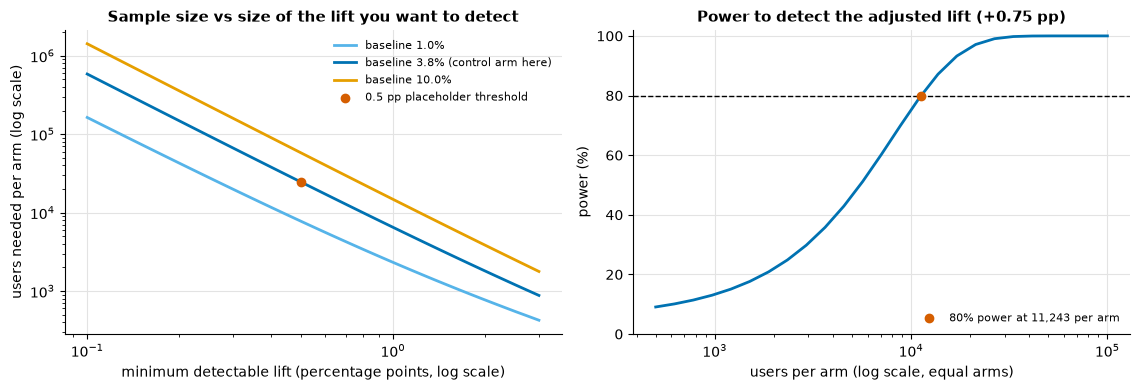

,lift to detect,"per arm, equal split","total, equal split","total, 85/15 split",control / treatment at 85/15
0.5 percentage points,0.500 pp,"24,516","49,032","97,681","14,652 / 83,029"
measured lift (raw),1.034 pp,"6,088","12,176","24,601","3,690 / 20,911"
measured lift (adjusted),0.749 pp,"11,243","22,486","45,107","6,766 / 38,341"
10% relative,0.382 pp,"41,416","82,832","164,447","24,667 / 139,780"


The real experiment had 2,096,937 control and 11,882,655 treated users. At that size the smallest lift it could detect with 80% power is only **0.040 pp**, compared with the 0.50 pp placeholder threshold. Sample size was never the problem here, which is why notebook 02 is about validity, not power.

In [4]:
p0 = R["power"]["baseline_rate"]
adj_lift = R["effect"]["visit_adjusted"]["diff"]
tab = R["power"]["table"]
row_adj = next(t for t in tab if t["label"] == "measured lift (adjusted)")
ss = sample_size_proportions(p0, adj_lift)
ctx.check(
    "users per arm for the adjusted lift",
    float(ss.n_control),
    float(row_adj["n_per_arm_equal"]),
    rtol=1e-9,
)

fig, (a, b) = plt.subplots(1, 2, figsize=(11.5, 4))
mdes = np.geomspace(0.001, 0.03, 40)
for base, color, ls in ((0.01, nb.SKY, "-"), (p0, nb.BLUE, "-"), (0.10, nb.ORANGE, "-")):
    ns = [sample_size_proportions(base, m).n_control for m in mdes]
    lab = f"baseline {base:.1%}" + (" (control arm here)" if base == p0 else "")
    a.plot(mdes * 100, ns, color=color, ls=ls, lw=2, label=lab)
a.scatter(
    [0.5],
    [sample_size_proportions(p0, 0.005).n_control],
    color=nb.VERMILLION,
    zorder=4,
    label="0.5 pp placeholder threshold",
)
a.set_xscale("log")
a.set_yscale("log")
a.set_xlabel("minimum detectable lift (percentage points, log scale)")
a.set_ylabel("users needed per arm (log scale)")
a.set_title("Sample size vs size of the lift you want to detect")
a.legend(fontsize=8)

curve = R["power"]["curve"]
b.plot(curve["n_per_arm"], np.array(curve["power"]) * 100, color=nb.BLUE, lw=2)
b.axhline(80, color=nb.BLACK, ls="--", lw=1)
b.scatter(
    [ss.n_control],
    [80],
    color=nb.VERMILLION,
    zorder=4,
    label=f"80% power at {n_(ss.n_control)} per arm",
)
b.set_xscale("log")
b.set_xlabel("users per arm (log scale, equal arms)")
b.set_ylabel("power (%)")
b.set_ylim(0, 102)
b.set_title(f"Power to detect the adjusted lift ({adj_lift * 100:+.2f} pp)")
b.legend(loc="lower right", fontsize=8)
fig.tight_layout()
ctx.savefig(fig, "power_sample_size")

display(
    pd.DataFrame(
        {
            "lift to detect": [f"{t['absolute_effect'] * 100:.3f} pp" for t in tab],
            "per arm, equal split": [n_(t["n_per_arm_equal"]) for t in tab],
            "total, equal split": [n_(t["total_equal"]) for t in tab],
            "total, 85/15 split": [n_(t["total_85_15"]) for t in tab],
            "control / treatment at 85/15": [
                f"{n_(t['n_control_85_15'])} / {n_(t['n_treatment_85_15'])}" for t in tab
            ],
        },
        index=[t["label"] for t in tab],
    )
)
arms = R["design"]["arms"]
mde_actual = R["power"]["mde_of_actual_experiment"]
nb.md(
    f"The real experiment had {n_(arms['control']['n'])} control and {n_(arms['treatment']['n'])} treated users. "
    f"At that size the smallest lift it could detect with 80% power is only "
    f"**{mde_actual * 100:.3f} pp**, compared with the {config.PRACTICAL_THRESHOLD * 100:.2f} pp placeholder threshold. "
    + (
        "Sample size was never the problem here, which is why notebook 02 is about validity, not power."
        if mde_actual < 0.2 * config.PRACTICAL_THRESHOLD
        else "Here the sample is small enough that power matters."
    )
)

## 3. A/A test: does the test cry wolf?

Take the treated users only and, many times, draw two random groups of the same size from them.
There is **no** difference between the groups by construction. A test at the 5% level should
call a difference "significant" in about 5% of the draws. This replays the pipeline's A/A
simulation (same seed, same draws), so the false-positive rate must match `results.json`.

- Check: A/A false positive rate: recomputed `0.047`, pipeline `0.047` (matches)

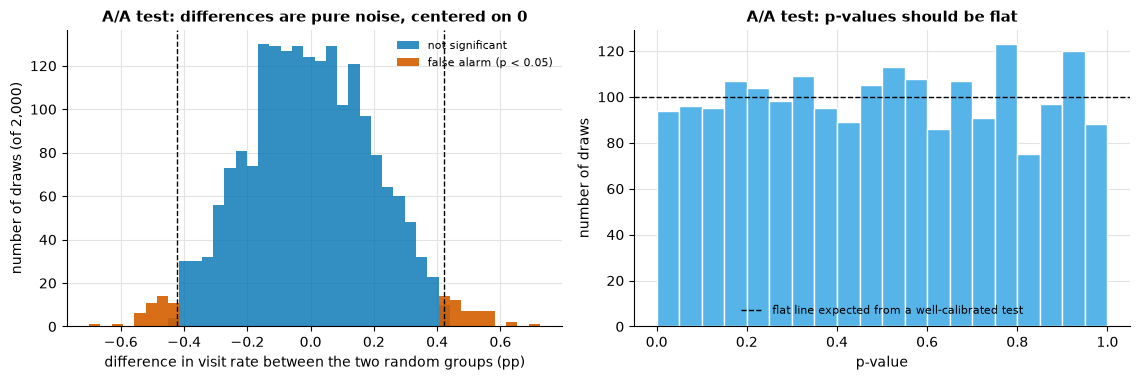

False-positive rate: **4.7%** over 2,000 draws of 20,000 users per group (95% interval 3.9% to 5.7%), against 5% expected. The expected rate sits inside the interval.

In [5]:
def visits(split: str, arm: int) -> np.ndarray:
    return con.execute(
        f"SELECT visit FROM criteo_split WHERE split = '{split}' AND treatment = {arm} ORDER BY row_id"
    ).fetchnumpy()["visit"]


vt = np.concatenate([visits(s, 1) for s in ("train", "val", "test")])
rng = np.random.default_rng(st.seed)
n_aa = min(st.aa_n_per_arm, len(vt) // 2)
diffs, pvals = np.empty(st.aa_reps), np.empty(st.aa_reps)
for i in range(st.aa_reps):
    idx = rng.choice(len(vt), size=2 * n_aa, replace=False)
    e = compare_proportions(int(vt[idx[:n_aa]].sum()), n_aa, int(vt[idx[n_aa:]].sum()), n_aa)
    diffs[i], pvals[i] = e.diff, e.p_value
fp = float(np.mean(pvals < config.ALPHA))
aa = R["validation"]["aa"]
ctx.check("A/A false positive rate", fp, aa["false_positive_rate"], rtol=1e-12)

p_bar = vt.mean()
se_theory = np.sqrt(2 * p_bar * (1 - p_bar) / n_aa)
fig, (a, b) = plt.subplots(1, 2, figsize=(11.5, 3.9))
edges = np.linspace(diffs.min() * 100, diffs.max() * 100, 41)
sig = pvals < config.ALPHA
a.hist(diffs[~sig] * 100, bins=edges, color=nb.BLUE, alpha=0.8, label="not significant")
a.hist(diffs[sig] * 100, bins=edges, color=nb.VERMILLION, alpha=0.9, label="false alarm (p < 0.05)")
for s in (-1, 1):
    a.axvline(s * 1.96 * se_theory * 100, color=nb.BLACK, ls="--", lw=1)
a.set_xlabel("difference in visit rate between the two random groups (pp)")
a.set_ylabel(f"number of draws (of {st.aa_reps:,})")
a.set_title("A/A test: differences are pure noise, centered on 0")
a.legend(fontsize=8)

b.hist(pvals, bins=np.linspace(0, 1, 21), color=nb.SKY, edgecolor="white")
b.axhline(
    st.aa_reps / 20,
    color=nb.BLACK,
    ls="--",
    lw=1,
    label="flat line expected from a well-calibrated test",
)
b.set_xlabel("p-value")
b.set_ylabel("number of draws")
b.set_title("A/A test: p-values should be flat")
b.legend(fontsize=8, loc="lower center")
fig.tight_layout()
ctx.savefig(fig, "aa_false_positives")

lo, hi = aa["ci95"]
nb.md(
    f"False-positive rate: **{pct(fp, 1)}** over {st.aa_reps:,} draws of {n_(n_aa)} users per group "
    f"(95% interval {pct(lo, 1)} to {pct(hi, 1)}), against {pct(aa['nominal'], 0)} expected. "
    f"{'The expected rate sits inside the interval.' if lo <= aa['nominal'] <= hi else 'The expected rate is OUTSIDE the interval.'}"
)

## 4. Power calibration

The calculator says a sample of N users per arm has 80% power to detect the measured lift. To
test that, draw samples of exactly that size from the real treated and control users, run the
test, and count how often it detects a positive lift.

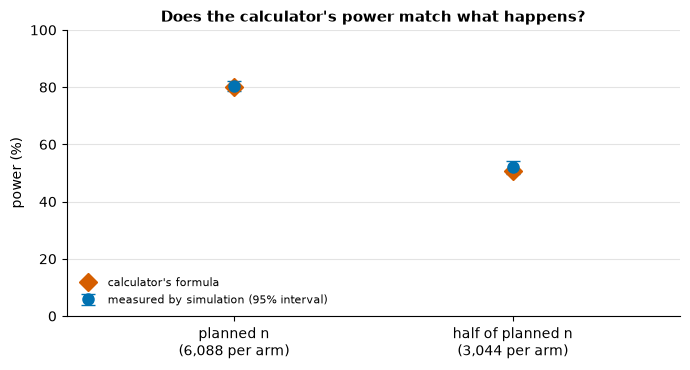

- planned n: formula 80.0%, measured 80.5% (95% interval 78.7% to 82.1%; formula inside the interval)
- half of planned n: formula 50.8%, measured 51.9% (95% interval 49.8% to 54.1%; formula inside the interval)

In [6]:
cases = R["validation"]["power"]
fig, ax = plt.subplots(figsize=(7, 3.8))
for i, c in enumerate(cases):
    ax.errorbar(
        [i],
        [c["empirical_power"] * 100],
        yerr=[
            [(c["empirical_power"] - c["ci95"][0]) * 100],
            [(c["ci95"][1] - c["empirical_power"]) * 100],
        ],
        fmt="o",
        color=nb.BLUE,
        capsize=5,
        ms=8,
        label="measured by simulation (95% interval)" if i == 0 else None,
    )
    ax.plot(
        [i],
        [c["nominal_power"] * 100],
        "D",
        color=nb.VERMILLION,
        ms=9,
        label="calculator's formula" if i == 0 else None,
    )
ax.set_xticks(range(len(cases)))
ax.set_xticklabels([f"{c['label']}\n({n_(c['n_per_arm'])} per arm)" for c in cases])
ax.set_xlim(-0.6, len(cases) - 0.4)
ax.set_ylim(0, 100)
ax.set_ylabel("power (%)")
ax.set_title("Does the calculator's power match what happens?")
ax.legend(loc="lower left", fontsize=8)
ax.grid(axis="x", visible=False)
fig.tight_layout()
ctx.savefig(fig, "power_calibration")

check_rows = []
for c in cases:
    inside = c["ci95"][0] <= c["nominal_power"] <= c["ci95"][1]
    check_rows.append(
        f"- {c['label']}: formula {pct(c['nominal_power'], 1)}, measured {pct(c['empirical_power'], 1)} (95% interval {pct(c['ci95'][0], 1)} to {pct(c['ci95'][1], 1)}; formula {'inside' if inside else 'OUTSIDE'} the interval)"
    )
nb.md("\n".join(check_rows))

## 5. What the decision rule does as the sample grows

Using the same real rows, draw samples at the planned size and at 4 and 16 times that size, and
apply the ship / run longer / do not ship rule at the placeholder threshold of 0.5 pp.

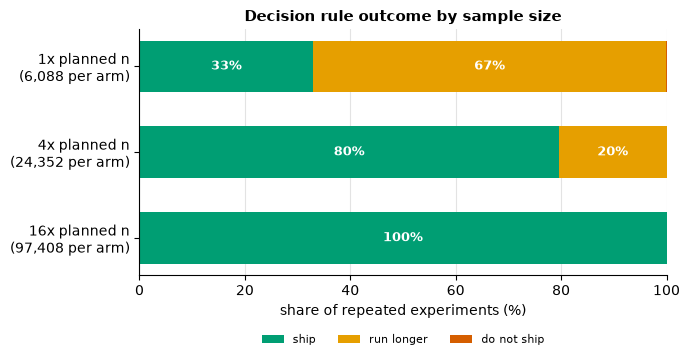

In [7]:
ops = R["validation"]["decision"]
fig, ax = plt.subplots(figsize=(7, 3.8))
left = np.zeros(len(ops))
for key, label, color in (
    ("ship", "ship", nb.GREEN),
    ("run_longer", "run longer", nb.ORANGE),
    ("dont_ship", "do not ship", nb.VERMILLION),
):
    vals = np.array([o[key] for o in ops]) * 100
    ax.barh(range(len(ops)), vals, left=left, color=color, label=label, height=0.6)
    for i, v in enumerate(vals):
        if v >= 6:
            ax.text(
                left[i] + v / 2,
                i,
                f"{v:.0f}%",
                ha="center",
                va="center",
                color="white",
                fontsize=9,
                fontweight="bold",
            )
    left += vals
ax.set_yticks(range(len(ops)))
ax.set_yticklabels([f"{o['multiplier']}x planned n\n({n_(o['n_per_arm'])} per arm)" for o in ops])
ax.invert_yaxis()
ax.set_xlabel("share of repeated experiments (%)")
ax.set_xlim(0, 100)
ax.set_title("Decision rule outcome by sample size")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.2), fontsize=8)
ax.grid(axis="y", visible=False)
fig.tight_layout()
ctx.savefig(fig, "decision_operating_characteristics")

## Summary

In [8]:
lin, cup = cu["linear"], cu["cupac"]
shift = (cu["raw"]["diff"] - cup["diff"]) * 100
nb.notes(
    "What this means",
    [
        f"Adjusting for what we know about each user cuts the variance of the lift estimate by "
        f"{pct(lin['variance_reduction'], 1)} (linear) and {pct(cup['variance_reduction'], 1)} (CUPAC), "
        f"so the same conclusion needs about {pct(lin['sample_size_ratio'], 0)} or "
        f"{pct(cup['sample_size_ratio'], 0)} of the users.",
        f"Detecting {row_adj['absolute_effect'] * 100:.2f} pp needs {n_(row_adj['n_per_arm_equal'])} users per arm "
        f"({n_(row_adj['total_85_15'])} in total with an 85% / 15% split). The real control arm "
        f"alone ({n_(arms['control']['n'])}) was {arms['control']['n'] / row_adj['n_control_85_15']:.0f} times "
        f"the control size that lift needs.",
        f"The A/A false-positive rate is {pct(fp, 1)} (expected {pct(aa['nominal'], 0)}; 95% interval "
        f"{pct(lo, 1)} to {pct(hi, 1)}), so the test "
        + (
            "is not crying wolf."
            if lo <= aa["nominal"] <= hi
            else "does NOT match its stated error rate."
        ),
        "The calculator's power matches simulation: "
        + "; ".join(
            f"{c['label']} {pct(c['nominal_power'], 1)} against {pct(c['empirical_power'], 1)}"
            for c in cases
        )
        + ".",
    ],
)
nb.notes(
    "What is weak",
    [
        "Criteo has no pre-period metric. The covariate is a function of the same 12 features, "
        f"and CUPED also moved the point estimate by {shift:+.2f} pp (raw minus CUPAC), so part of "
        "what it does here is correct for arm imbalance, not only reduce noise.",
        "The A/A test splits one arm in two. It checks the statistics, not the assignment "
        "mechanism, so it cannot reveal the arm imbalance found in notebook 02.",
        "Power uses the normal approximation, a fixed sample size and a single look at the data. "
        "Repeated peeking or very rare outcomes need other methods.",
        "The simulations resample the real rows without replacement, so they describe this "
        "experiment's population only. They are checks of the toolkit, not new evidence about the ad.",
    ],
)

### What this means

- Adjusting for what we know about each user cuts the variance of the lift estimate by 25.0% (linear) and 30.5% (CUPAC), so the same conclusion needs about 75% or 70% of the users.
- Detecting 0.75 pp needs 11,243 users per arm (45,107 in total with an 85% / 15% split). The real control arm alone (2,096,937) was 310 times the control size that lift needs.
- The A/A false-positive rate is 4.7% (expected 5%; 95% interval 3.9% to 5.7%), so the test is not crying wolf.
- The calculator's power matches simulation: planned n 80.0% against 80.5%; half of planned n 50.8% against 51.9%.

### What is weak

- Criteo has no pre-period metric. The covariate is a function of the same 12 features, and CUPED also moved the point estimate by +0.41 pp (raw minus CUPAC), so part of what it does here is correct for arm imbalance, not only reduce noise.
- The A/A test splits one arm in two. It checks the statistics, not the assignment mechanism, so it cannot reveal the arm imbalance found in notebook 02.
- Power uses the normal approximation, a fixed sample size and a single look at the data. Repeated peeking or very rare outcomes need other methods.
- The simulations resample the real rows without replacement, so they describe this experiment's population only. They are checks of the toolkit, not new evidence about the ad.